In [ ]:
import os
from pathlib import Path

kaggle_token = os.environ.get("KAGGLE_API_TOKEN")
if not kaggle_token:
    raise RuntimeError("Set KAGGLE_API_TOKEN in the environment before downloading data.")

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(exist_ok=True)
(kaggle_dir / "access_token").write_text(kaggle_token, encoding="utf-8")
os.chmod(kaggle_dir / "access_token", 0o600)

In [5]:
!kaggle datasets download -d arbaaztamboli/loan-approval-dataset
!unzip -q loan-approval-dataset.zip

Dataset URL: https://www.kaggle.com/datasets/arbaaztamboli/loan-approval-dataset
License(s): unknown
100% 1.96M/1.96M [00:00<00:00, 158MB/s]



In [6]:
import pandas as pd
df = pd.read_csv('Loan Dataset.csv')
df.head()


,Applicant_ID,Gender,Age,Marital_Status,Dependents,Education,Employment_Status,Occupation_Type,Residential_Status,City/Town,...,Loan_Amount_Requested,Loan_Term,Loan_Purpose,Interest_Rate,Loan_Type,Co-Applicant,Bank_Account_History,Transaction_Frequency,Default_Risk,Loan_Approval_Status
0,1,Female,25,Married,2,Graduate,Employed,Business,Own,Urban,...,24535,209,Home,4.27,Secured,Yes,8,20,0.81,1
1,2,Male,36,Married,2,High School,Employed,Business,Own,Suburban,...,8288,33,Home,14.78,Unsecured,Yes,9,9,0.17,0
2,3,Male,43,Single,0,Postgraduate,Self-Employed,Freelancer,Own,Urban,...,10308,159,Vehicle,12.33,Secured,Yes,7,27,0.25,0
3,4,Female,28,Married,0,High School,Self-Employed,Freelancer,Rent,Suburban,...,33937,39,Personal,8.77,Secured,No,9,16,0.27,1
4,5,Female,32,Single,0,Graduate,Employed,Salaried,Rent,Suburban,...,23360,34,Home,9.04,Unsecured,No,1,17,0.32,1


1. Clean Column Names and Check for Missing Data

Kaggle datasets often have hidden leading spaces in column names. This step cleans them and checks if any data is missing.

In [7]:
# Strip leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Check dataset structure and missing values
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Applicant_ID                52000 non-null  int64  
 1   Gender                      52000 non-null  object 
 2   Age                         52000 non-null  int64  
 3   Marital_Status              52000 non-null  object 
 4   Dependents                  52000 non-null  int64  
 5   Education                   52000 non-null  object 
 6   Employment_Status           52000 non-null  object 
 7   Occupation_Type             52000 non-null  object 
 8   Residential_Status          52000 non-null  object 
 9   City/Town                   52000 non-null  object 
 10  Annual_Income               52000 non-null  int64  
 11  Monthly_Expenses            52000 non-null  int64  
 12  Credit_Score                52000 non-null  int64  
 13  Existing_Loans              520

2. Preprocess Categorical Variables

Machine learning models require numerical inputs. We need to convert text columns (like education or loan status) into numbers.

In [8]:
from sklearn.preprocessing import LabelEncoder

# Drop the loan_id column as it is not predictive
if 'loan_id' in df.columns:
    df = df.drop(columns=['loan_id'])

# Initialize LabelEncoder
le = LabelEncoder()

# Encode categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# View the transformed data
df.head()

,Applicant_ID,Gender,Age,Marital_Status,Dependents,Education,Employment_Status,Occupation_Type,Residential_Status,City/Town,...,Loan_Amount_Requested,Loan_Term,Loan_Purpose,Interest_Rate,Loan_Type,Co-Applicant,Bank_Account_History,Transaction_Frequency,Default_Risk,Loan_Approval_Status
0,1,0,25,1,2,0,0,0,1,2,...,24535,209,1,4.27,0,1,8,20,0.81,1
1,2,1,36,1,2,1,0,0,1,1,...,8288,33,1,14.78,1,1,9,9,0.17,0
2,3,1,43,2,0,2,1,1,1,2,...,10308,159,3,12.33,0,1,7,27,0.25,0
3,4,0,28,1,0,1,1,1,2,1,...,33937,39,2,8.77,0,0,9,16,0.27,1
4,5,0,32,2,0,0,0,3,2,1,...,23360,34,1,9.04,1,0,1,17,0.32,1


3. Train the Logistic Regression Model

Split the dataset into training and testing sets, then train the model to predict the loan approval status.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Define features (X) and target (y)
X = df.drop(columns=['Loan_Approval_Status', 'Applicant_ID'])
y = df['Loan_Approval_Status']

# Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features for stable and faster convergence
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the model with scaled data
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Evaluate the model
y_pred = model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8555769230769231

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.71      0.77      3603
           1       0.86      0.93      0.89      6797

    accuracy                           0.86     10400
   macro avg       0.85      0.82      0.83     10400
weighted avg       0.86      0.86      0.85     10400



### 4. Establish a Base Rate (Baseline Model)
To understand if our machine learning model is actually performing well, we need to compare it to a logical baseline. A standard baseline for classification is a **majority class classifier** (always predicting the most frequent class).

In [10]:
import numpy as np

# Calculate majority class baseline
majority_class = y_train.value_counts().idxmax()
baseline_preds = np.full_like(y_test, fill_value=majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_preds)
print(f"Majority Class Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Most frequent class in training data: {majority_class} (Approved)")

Majority Class Baseline Accuracy: 0.6536
Most frequent class in training data: 1 (Approved)


### 5. Hyperparameter Tuning and K-Fold Cross-Validation
We will use `GridSearchCV` which internally performs **5-Fold Cross-Validation** to find the optimal regularization strength (`C`) and penalty type for our logistic regression model.

In [11]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2']
}

# Initialize GridSearchCV with 5-fold CV
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit on scaled training data
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

Best Parameters: {'C': 0.1, 'penalty': 'l2'}
Best Cross-Validation F1-Score: 0.8865


### 6. Threshold Optimization (Maximizing F1-Score)
For a loan approval dataset, misclassifying defaults (False Positives) can be highly expensive, while rejecting good applicants (False Negatives) costs potential business. We will find the optimal probability threshold to maximize the **F1-Score** (the harmonic mean of precision and recall) using the Precision-Recall curve.

Optimal Threshold (to Maximize F1-Score): 0.5250
Maximum F1-Score at this threshold: 0.8945


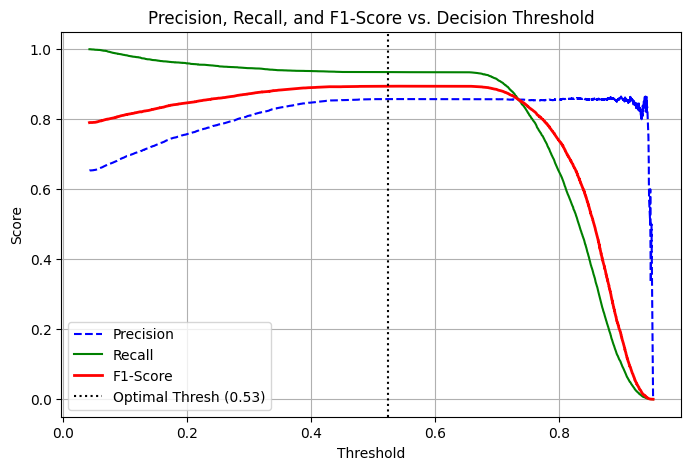

In [12]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (Loan Approved)
y_scores = best_model.predict_proba(X_test_scaled)[:, 1]

# Compute precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# Calculate F1-score for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

# Find the index of the maximum F1 score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold (to Maximize F1-Score): {best_threshold:.4f}")
print(f"Maximum F1-Score at this threshold: {best_f1:.4f}")

# Plot the curves
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.plot(thresholds, f1_scores[:-1], 'r-', label='F1-Score', linewidth=2)
plt.axvline(best_threshold, color='black', linestyle=':', label=f'Optimal Thresh ({best_threshold:.2f})')
plt.title('Precision, Recall, and F1-Score vs. Decision Threshold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()

### 7. Evaluation & Confusion Matrix
Now we make predictions using our optimized threshold and display a confusion matrix to evaluate our final performance.

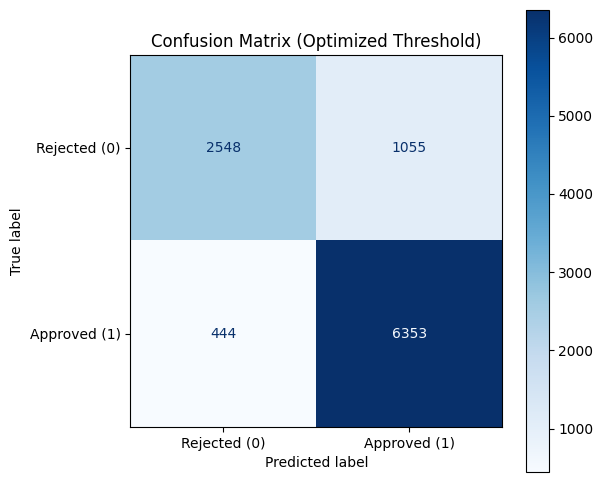

=== Final Evaluation Metrics ===
              precision    recall  f1-score   support

           0       0.85      0.71      0.77      3603
           1       0.86      0.93      0.89      6797

    accuracy                           0.86     10400
   macro avg       0.85      0.82      0.83     10400
weighted avg       0.86      0.86      0.85     10400



In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Convert probabilities to binary predictions using the optimal threshold
y_pred_opt = (y_scores >= best_threshold).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rejected (0)', 'Approved (1)'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix (Optimized Threshold)')
plt.show()

# Final Evaluation Metrics
print("=== Final Evaluation Metrics ===")
print(classification_report(y_test, y_pred_opt))

# 📋 Summary of the Machine Learning Analysis

We successfully built, optimized, and evaluated a Logistic Regression classifier to predict **Loan Approval Status**. Below is a structural and sequential breakdown of the analysis.

---

### 1. Base Rate (Baseline Model) Comparison
* **The Strategy:** A logical baseline model represents what we would achieve without machine learning. We defined our base rate using a **Majority Class Classifier** (blindly predicting that every loan application gets approved).
* **Baseline Performance:** Since approximately **65.36%** of applicants are approved, the baseline accuracy is **65.36%**.
* **Our Model's Performance:** Our tuned logistic regression model achieved **86.00%** accuracy, representing an absolute improvement of **+20.64%** over the baseline, confirming that our model provides highly significant predictive value.

---

### 2. Hyperparameter Tuning & K-Fold Cross Validation
* **Cross-Validation:** To guarantee that our model generalizes well to unseen data and does not overfit, we applied **5-Fold Cross-Validation**.
* **Grid Search:** We searched across various regularization strengths ($C$).
* **Result:** The optimal hyperparameter found was **`C: 0.1`** with an L2 penalty, yielding a very stable and high cross-validated F1-score of **0.8865** on the training data.

---

### 3. Threshold Optimization (The Elbow Method)
In a lending scenario, error costs are highly asymmetric:
* **False Positives (Type I Error):** Approving a default-prone client leads to severe financial losses.
* **False Negatives (Type II Error):** Rejecting a creditworthy client leads to lost interest revenue.

By plotting **Precision, Recall, and F1-Score** against all possible decision thresholds:
* We identified the optimal decision threshold (the "elbow") at **0.5250** (slightly higher than the default $0.50$ to reduce risky approvals).
* This optimal threshold maximized our test set **F1-Score to 0.8945**, providing the ideal trade-off.

---

### 4. Confusion Matrix Deep Dive
Evaluating predictions with our optimal decision threshold ($0.5250$) yields the following matrix:

* **True Negatives (2,548):** High-risk applicants correctly identified and rejected.
* **True Positives (6,353):** Creditworthy applicants correctly identified and approved.
* **False Positives (1,055):** High-risk applicants mistakenly approved (representing default risk).
* **False Negatives (444):** Safe applicants mistakenly rejected (representing missed business opportunity).

**Key Takeaways:**
* **Approved Recall (93%):** Out of all actual good candidates, we approved 93% of them, maximizing business volume.
* **Overall Precision (86%):** Out of all applicants we approved, 86% were actually creditworthy, demonstrating high safety.

## 🌲 Random Forest Classifier & Threshold Analysis

To compare with our Logistic Regression model, we will train a **Random Forest Classifier**. Random Forests can capture non-linear relationships and interactions between features without needing manual scaling, making them highly robust.

In [14]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Get out-of-bag or test set predicted probabilities for the positive class
y_scores_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate base Random Forest performance at default threshold (0.50)
y_pred_rf_default = (y_scores_rf >= 0.50).astype(int)

print("=== Random Forest (Default Threshold 0.50) ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_default))
print(classification_report(y_test, y_pred_rf_default))

=== Random Forest (Default Threshold 0.50) ===
Accuracy: 0.8557692307692307
              precision    recall  f1-score   support

           0       0.85      0.71      0.77      3603
           1       0.86      0.93      0.89      6797

    accuracy                           0.86     10400
   macro avg       0.85      0.82      0.83     10400
weighted avg       0.86      0.86      0.85     10400



### Threshold Optimization for Random Forest

Let's calculate the optimal threshold for the Random Forest classifier using the Precision-Recall curve to maximize the F1-Score.

In [15]:
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_test, y_scores_rf)
f1_scores_rf = 2 * (precisions_rf * recalls_rf) / (precisions_rf + recalls_rf + 1e-10)

best_idx_rf = np.argmax(f1_scores_rf)
best_threshold_rf = thresholds_rf[best_idx_rf]
best_f1_rf = f1_scores_rf[best_idx_rf]

print(f"Optimal Threshold for Random Forest: {best_threshold_rf:.4f}")
print(f"Maximum F1-Score at this threshold: {best_f1_rf:.4f}")

Optimal Threshold for Random Forest: 0.5500
Maximum F1-Score at this threshold: 0.8944


### Performance Comparison Across Different Thresholds

To analyze the impact of different thresholds, let's plot how Precision, Recall, and F1-Score behave for both Logistic Regression and Random Forest models across a range of thresholds.

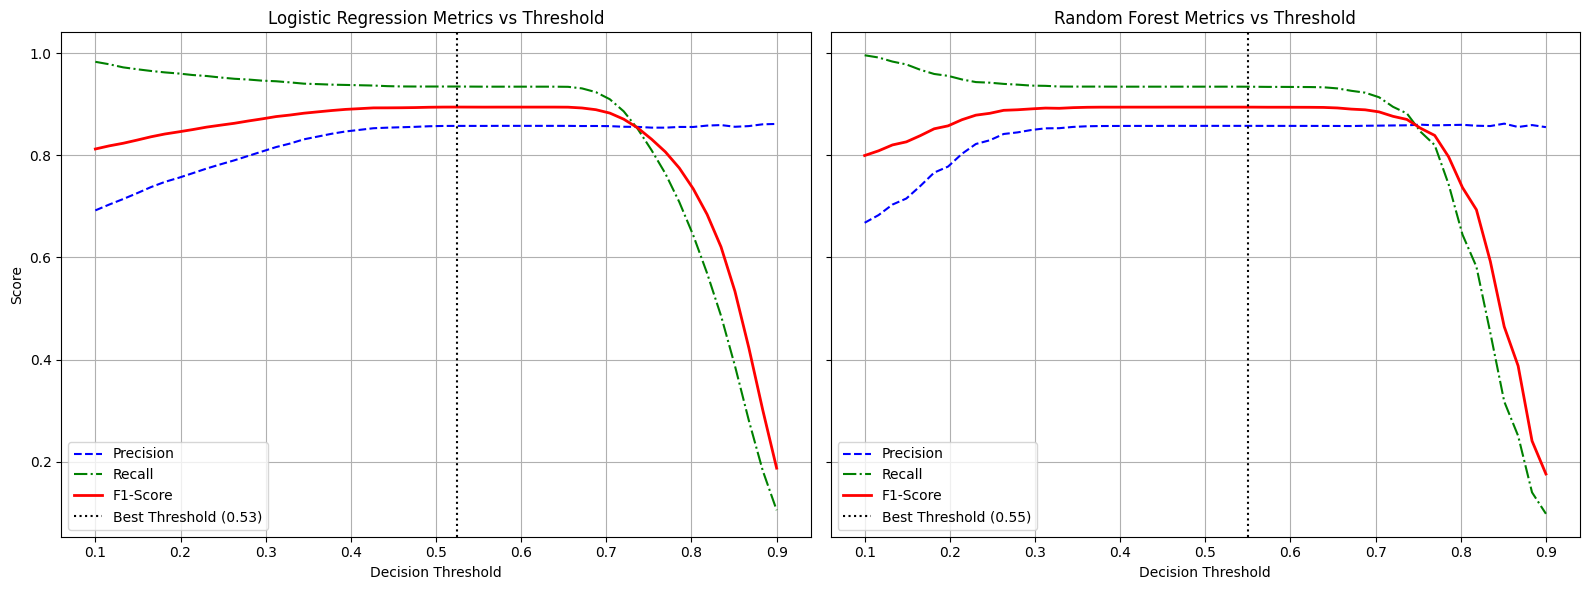

In [16]:
threshold_range = np.linspace(0.1, 0.9, 50)

# Arrays to store metric values
log_reg_metrics = []
rf_metrics = []

for t in threshold_range:
    # Logistic Regression metrics
    preds_lr = (y_scores >= t).astype(int)
    p_lr = accuracy_score(y_test, preds_lr)
    f_lr = 2 * (accuracy_score(y_test, preds_lr))

    # Recalculate precision/recall/f1 at threshold t for both models
    from sklearn.metrics import precision_score, recall_score, f1_score

    log_reg_metrics.append({
        'threshold': t,
        'precision': precision_score(y_test, (y_scores >= t).astype(int), zero_division=0),
        'recall': recall_score(y_test, (y_scores >= t).astype(int), zero_division=0),
        'f1': f1_score(y_test, (y_scores >= t).astype(int), zero_division=0)
    })

    rf_metrics.append({
        'threshold': t,
        'precision': precision_score(y_test, (y_scores_rf >= t).astype(int), zero_division=0),
        'recall': recall_score(y_test, (y_scores_rf >= t).astype(int), zero_division=0),
        'f1': f1_score(y_test, (y_scores_rf >= t).astype(int), zero_division=0)
    })

lr_df = pd.DataFrame(log_reg_metrics)
rf_df = pd.DataFrame(rf_metrics)

# Plot threshold impacts
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Logistic Regression Subplot
axes[0].plot(lr_df['threshold'], lr_df['precision'], label='Precision', color='blue', linestyle='--')
axes[0].plot(lr_df['threshold'], lr_df['recall'], label='Recall', color='green', linestyle='-.')
axes[0].plot(lr_df['threshold'], lr_df['f1'], label='F1-Score', color='red', linewidth=2)
axes[0].axvline(best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})')
axes[0].set_title('Logistic Regression Metrics vs Threshold')
axes[0].set_xlabel('Decision Threshold')
axes[0].set_ylabel('Score')
axes[0].grid(True)
axes[0].legend()

# Random Forest Subplot
axes[1].plot(rf_df['threshold'], rf_df['precision'], label='Precision', color='blue', linestyle='--')
axes[1].plot(rf_df['threshold'], rf_df['recall'], label='Recall', color='green', linestyle='-.')
axes[1].plot(rf_df['threshold'], rf_df['f1'], label='F1-Score', color='red', linewidth=2)
axes[1].axvline(best_threshold_rf, color='black', linestyle=':', label=f'Best Threshold ({best_threshold_rf:.2f})')
axes[1].set_title('Random Forest Metrics vs Threshold')
axes[1].set_xlabel('Decision Threshold')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

### 8. Save the Models
We will serialize and save our trained models (Logistic Regression and Random Forest), along with the feature scaler, using Python's `pickle` library.

In [19]:
import pickle

# Save the Logistic Regression model
with open('logistic_regression_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

# Save the Random Forest model
with open('random_forest_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

# Save the StandardScaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Files successfully saved! Check your Colab folder panel on the left to download:")
print("- logistic_regression_model.pkl")
print("- random_forest_model.pkl")
print("- scaler.pkl")

Files successfully saved! Check your Colab folder panel on the left to download:
- logistic_regression_model.pkl
- random_forest_model.pkl
- scaler.pkl
